# O desemprego caiu em todos os estados?

**Pergunta:** o Brasil chegou ao menor desemprego da série histórica da PNAD Contínua. Essa recuperação chegou a todos os estados, ou alguém ficou para trás?

**Dados:** taxa de desocupação trimestral da PNAD Contínua (IBGE, [tabela 4099](https://sidra.ibge.gov.br/tabela/4099)), para Brasil, 5 regiões e 27 UFs, do 1º trimestre de 2012 ao 2º trimestre de 2026.

**Roteiro:**
1. Preparação dos dados e tratamento da sazonalidade
2. Brasil: do pico de 2021 ao menor nível da série
3. Estados: quem já voltou ao nível de 2014 e quem não voltou
4. Rio de Janeiro: a recuperação mais incompleta do Sudeste
5. Regiões: a distância relativa entre Nordeste e Sul
6. Limitações

In [1]:
from decimal import Decimal, ROUND_HALF_UP
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

# Paleta: azul para o destaque, laranja para o alerta, cinza para o contexto
AZUL, LARANJA, CINZA, CINZA_CLARO = "#2a78d6", "#eb6834", "#8a8984", "#c9c8c2"
TEXTO, TEXTO_2, FUNDO = "#0b0b0b", "#52514e", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "font.size": 11, "axes.edgecolor": CINZA_CLARO, "axes.labelcolor": TEXTO_2,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.solid_capstyle": "round",
})
IMG = Path("../img")
IMG.mkdir(exist_ok=True)


def pct(x, casas=1):
    """Formata no padrão brasileiro, com arredondamento comercial (5,55 -> 5,6)."""
    arred = Decimal(str(round(x, 6))).quantize(Decimal(1).scaleb(-casas), ROUND_HALF_UP)
    return f"{arred}".replace(".", ",")


def finalizar(fig, titulo, subtitulo, arquivo):
    """Título, subtítulo e fonte em posições fixas (em polegadas), depois salva a imagem."""
    h = fig.get_figheight()
    fig.tight_layout(rect=(0, 0.35 / h, 1, 1 - 0.95 / h))
    fig.text(0.015, 1 - 0.28 / h, titulo, fontsize=14, fontweight="bold", color=TEXTO, va="top")
    fig.text(0.015, 1 - 0.6 / h, subtitulo, fontsize=10.5, color=TEXTO_2, va="top")
    fig.text(0.015, 0.1 / h, "Fonte: IBGE, PNAD Contínua (tabela 4099). Elaboração: Jonathan Silva de Sá.",
             fontsize=8.5, color=TEXTO_2)
    fig.savefig(IMG / arquivo, dpi=200)
    plt.show()


def tri(p):
    return f"{p.quarter}º tri/{p.year}"

## 1. Preparação

O arquivo `data/desocupacao_trimestral.csv` é gerado por `scripts/baixar_dados.py`, que consulta a API do IBGE. Uma linha por local e trimestre.

In [2]:
df = pd.read_csv("../data/desocupacao_trimestral.csv", dtype={"codigo": str})
df["periodo"] = pd.PeriodIndex.from_fields(year=df["ano"], quarter=df["trimestre"], freq="Q")
df = df.sort_values(["nivel", "codigo", "periodo"]).reset_index(drop=True)

print(f"{len(df):,} linhas | {df['periodo'].min()} a {df['periodo'].max()}".replace(",", "."))
df.groupby("nivel").agg(locais=("codigo", "nunique"), linhas=("codigo", "size"))

1.914 linhas | 2012Q1 a 2026Q2


,locais,linhas
nivel,,
Brasil,1,58
Região,5,290
UF,27,1566


### Por que usar a média de 4 trimestres

O desemprego tem sazonalidade: sobe todo 1º trimestre, quando os temporários de fim de ano são dispensados. Comparar um 1º trimestre com um 4º trimestre mistura tendência com época do ano.

In [3]:
br = df[df["nivel"] == "Brasil"].set_index("periodo")["taxa_desocupacao"]
desvio = (br - br.groupby(br.index.year).transform("mean")).groupby(br.index.quarter).mean()
desvio.rename_axis("trimestre").rename("desvio médio vs. média do ano (p.p.)").round(2).to_frame()

,desvio médio vs. média do ano (p.p.)
trimestre,
1,0.58
2,0.08
3,-0.12
4,-0.59


O 1º trimestre fica, em média, 0,6 ponto acima da média do ano, e o 4º trimestre 0,6 abaixo: mais de 1 ponto de diferença só pela época do ano. Por isso a análise usa a **média móvel de 4 trimestres**: cada ponto é a média do último ano, que sempre contém um trimestre de cada tipo. A média de 2014 (1º ao 4º trimestre) é a referência de antes da crise de 2015–2016.

In [4]:
df["media_4t"] = (df.groupby(["nivel", "codigo"])["taxa_desocupacao"]
                    .transform(lambda s: s.rolling(4).mean()))

ULTIMO = df["periodo"].max()
REF_2014 = pd.Period("2014Q4")   # média móvel no 4º tri = média do ano de 2014
print(f"Último trimestre: {tri(ULTIMO)} | 'atual' = média de {tri(ULTIMO - 3)} a {tri(ULTIMO)}")

Último trimestre: 2º tri/2026 | 'atual' = média de 3º tri/2025 a 2º tri/2026


## 2. Brasil: do pico de 2021 ao menor nível da série

In [5]:
brasil = df[df["nivel"] == "Brasil"].set_index("periodo")
pico = brasil["media_4t"].idxmax()
resumo_br = {
    "média de 2014": brasil.loc[REF_2014, "media_4t"],
    f"pico ({pico})": brasil["media_4t"].max(),
    "últimos 4 trimestres": brasil.loc[ULTIMO, "media_4t"],
    "menor média da série": brasil["media_4t"].min(),
}
{k: pct(v) + "%" for k, v in resumo_br.items()}

{'média de 2014': '6,9%',
 'pico (2021Q2)': '14,6%',
 'últimos 4 trimestres': '5,6%',
 'menor média da série': '5,6%'}

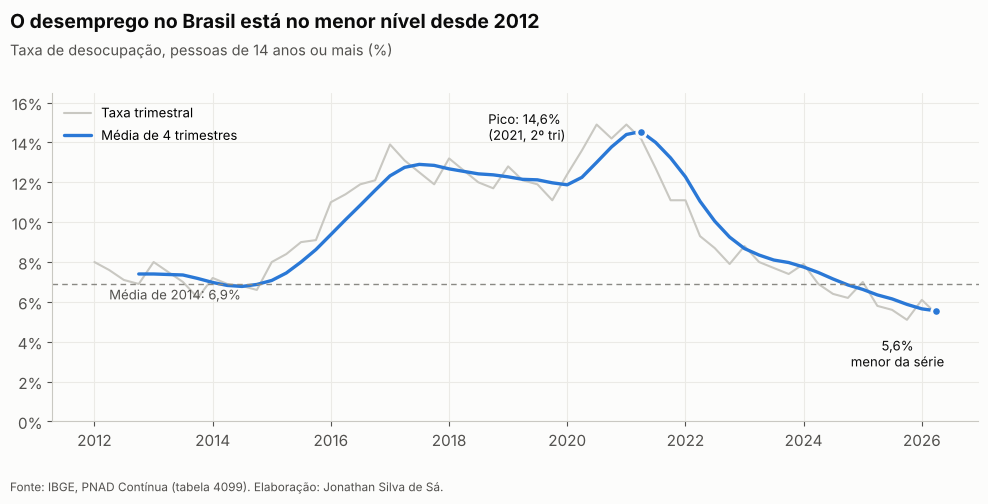

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.2))
x = brasil.index.to_timestamp()
ax.plot(x, brasil["taxa_desocupacao"], color=CINZA_CLARO, lw=1.5, label="Taxa trimestral")
ax.plot(x, brasil["media_4t"], color=AZUL, lw=2.4, label="Média de 4 trimestres")
ax.axhline(brasil.loc[REF_2014, "media_4t"], color=CINZA, lw=1, ls=(0, (4, 3)))
ax.text(x[1], brasil.loc[REF_2014, "media_4t"] - 0.75, f"Média de 2014: {pct(brasil.loc[REF_2014, 'media_4t'])}%",
        color=TEXTO_2, fontsize=9.5)

xp, yp = pico.to_timestamp(), brasil.loc[pico, "media_4t"]
ax.scatter([xp], [yp], s=46, color=AZUL, edgecolor=FUNDO, lw=2, zorder=3)
ax.annotate(f"Pico: {pct(yp)}%\n({pico.year}, {pico.quarter}º tri)", (xp, yp), xytext=(-110, -6),
            textcoords="offset points", fontsize=9.5, color=TEXTO)
xu, yu = ULTIMO.to_timestamp(), brasil.loc[ULTIMO, "media_4t"]
ax.scatter([xu], [yu], s=46, color=AZUL, edgecolor=FUNDO, lw=2, zorder=3)
ax.annotate(f"{pct(yu)}%\nmenor da série", (xu, yu), xytext=(-28, -40),
            textcoords="offset points", fontsize=9.5, color=TEXTO, ha="center")

ax.set_ylim(0, 16.5)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.legend(loc="upper left", frameon=False, fontsize=9.5)
finalizar(fig, "O desemprego no Brasil está no menor nível desde 2012",
          "Taxa de desocupação, pessoas de 14 anos ou mais (%)", "01_brasil.png")

O desemprego quase dobrou entre 2014 e a recessão de 2015–2016, subiu de novo na pandemia e, desde 2021, caiu sem interrupção até o menor nível da série, abaixo inclusive de 2014.

## 3. Estados: quem já voltou ao nível de 2014

In [7]:
ufs = df[df["nivel"] == "UF"]

def resumir(g):
    s = g.set_index("periodo")["media_4t"]
    return pd.Series({
        "media_2014": s[REF_2014],
        "pico": s.max(),
        "quando_pico": s.idxmax(),
        "atual": s[ULTIMO],
        "menor_da_serie_agora": s.idxmin() == ULTIMO,
    })

estados = (ufs.groupby(["sigla", "local", "regiao"])[["periodo", "media_4t"]]
              .apply(resumir).reset_index())
estados["vs_2014_pp"] = estados["atual"] - estados["media_2014"]
estados["queda_do_pico_pp"] = estados["pico"] - estados["atual"]

acima_2014 = estados[estados["vs_2014_pp"] > 0].sort_values("vs_2014_pp", ascending=False)
print(f"UFs no menor nível da própria série: {estados['menor_da_serie_agora'].sum()} de 27")
print(f"UFs acima da média de 2014: {len(acima_2014)} -> {', '.join(acima_2014['local'])}")
acima_2014[["local", "media_2014", "pico", "atual", "vs_2014_pp"]].round(2)

UFs no menor nível da própria série: 18 de 27
UFs acima da média de 2014: 3 -> Piauí, Rio de Janeiro, Pernambuco


,local,media_2014,pico,atual,vs_2014_pp
16,Piauí,6.60,14.05,8.18,1.58
18,Rio de Janeiro,6.30,19.12,7.20,0.90
15,Pernambuco,8.25,20.48,9.08,0.83


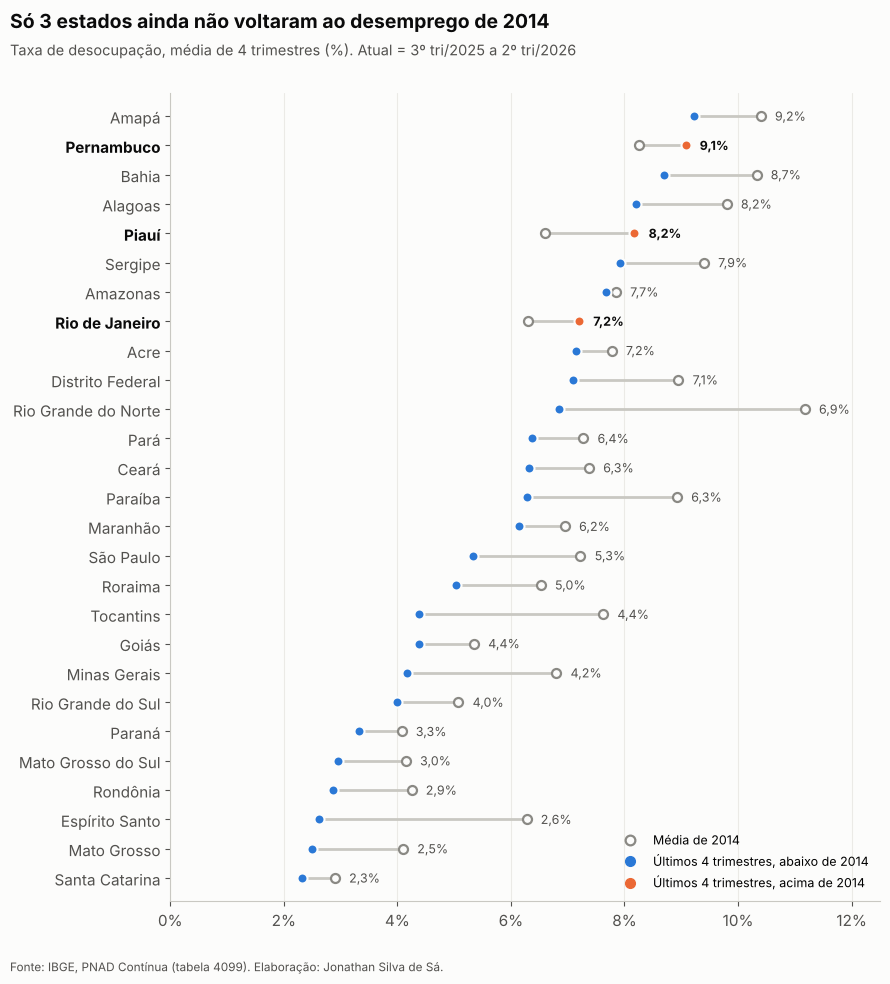

In [8]:
ordem = estados.sort_values("atual").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 10))
for i, r in ordem.iterrows():
    cor = LARANJA if r["vs_2014_pp"] > 0 else AZUL
    ax.plot([r["media_2014"], r["atual"]], [i, i], color=CINZA_CLARO, lw=2, zorder=1)
    ax.scatter(r["media_2014"], i, s=42, facecolor=FUNDO, edgecolor=CINZA, lw=1.6, zorder=2)
    ax.scatter(r["atual"], i, s=52, color=cor, edgecolor=FUNDO, lw=1.5, zorder=3)
    ax.text(max(r["media_2014"], r["atual"]) + 0.25, i, f"{pct(r['atual'])}%",
            va="center", fontsize=9, color=TEXTO if r["vs_2014_pp"] > 0 else TEXTO_2,
            fontweight="bold" if r["vs_2014_pp"] > 0 else "normal")

ax.set_yticks(range(len(ordem)), ordem["local"])
for rotulo, (_, r) in zip(ax.get_yticklabels(), ordem.iterrows()):
    if r["vs_2014_pp"] > 0:
        rotulo.set_fontweight("bold"); rotulo.set_color(TEXTO)
ax.set_ylim(-0.8, len(ordem) - 0.2)
ax.set_xlim(0, 12.5)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.grid(axis="y", visible=False)

legenda = [
    plt.Line2D([], [], marker="o", ls="", mfc=FUNDO, mec=CINZA, mew=1.6, ms=7, label="Média de 2014"),
    plt.Line2D([], [], marker="o", ls="", color=AZUL, ms=7, label="Últimos 4 trimestres, abaixo de 2014"),
    plt.Line2D([], [], marker="o", ls="", color=LARANJA, ms=7, label="Últimos 4 trimestres, acima de 2014"),
]
ax.legend(handles=legenda, loc="lower right", frameon=False, fontsize=9)
finalizar(fig, "Só 3 estados ainda não voltaram ao desemprego de 2014",
          f"Taxa de desocupação, média de 4 trimestres (%). Atual = {tri(ULTIMO - 3)} a {tri(ULTIMO)}",
          "02_estados_vs_2014.png")

Em 24 estados o desemprego dos últimos 4 trimestres é menor que o de 2014, e em 18 deles é o menor da série. Os três que não voltaram são **Piauí, Rio de Janeiro e Pernambuco**. O Piauí é um caso diferente dos outros dois: teve o menor pico do Nordeste, mas 2014 foi o seu menor desemprego da série e ele nunca mais voltou a esse nível.

## 4. Rio de Janeiro: a recuperação mais incompleta do Sudeste

In [9]:
sudeste = (ufs[ufs["regiao"] == "Sudeste"]
             .pivot(index="periodo", columns="sigla", values="media_4t")
             .dropna())
rank = estados.assign(r2014=estados["media_2014"].rank(ascending=False),
                      ratual=estados["atual"].rank(ascending=False)).set_index("sigla")
print(f"RJ: média de 2014 {pct(rank.loc['RJ', 'media_2014'])}% | pico {pct(rank.loc['RJ', 'pico'])}% "
      f"| atual {pct(rank.loc['RJ', 'atual'])}%")
print(f"Posição do RJ entre as 27 UFs (1 = maior desemprego): "
      f"{rank.loc['RJ', 'r2014']:.0f}ª em 2014 -> {rank.loc['RJ', 'ratual']:.0f}ª agora")
rank.loc[["RJ", "SP", "MG", "ES"], ["media_2014", "pico", "atual", "vs_2014_pp"]].round(2)

RJ: média de 2014 6,3% | pico 19,1% | atual 7,2%
Posição do RJ entre as 27 UFs (1 = maior desemprego): 19ª em 2014 -> 8ª agora


,media_2014,pico,atual,vs_2014_pp
sigla,,,,
RJ,6.30,19.12,7.20,0.90
SP,7.22,14.88,5.32,-1.90
MG,6.80,13.32,4.18,-2.62
ES,6.28,13.80,2.62,-3.65


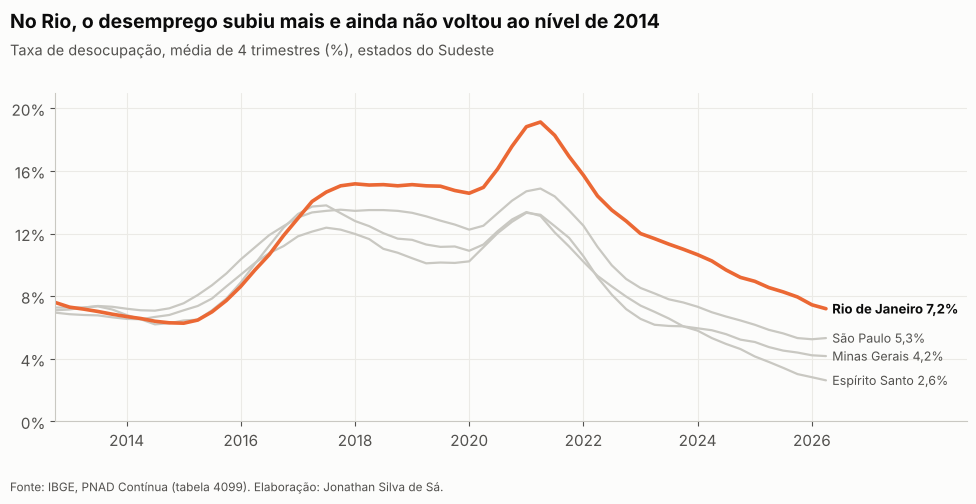

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.2))
x = sudeste.index.to_timestamp()
nomes = {"SP": "São Paulo", "MG": "Minas Gerais", "ES": "Espírito Santo"}
for sigla, nome in nomes.items():
    ax.plot(x, sudeste[sigla], color=CINZA_CLARO, lw=1.6)
    ax.text(x[-1] + pd.Timedelta(days=40), sudeste[sigla].iloc[-1], f"{nome} {pct(sudeste[sigla].iloc[-1])}%",
            va="center", fontsize=9, color=TEXTO_2)
ax.plot(x, sudeste["RJ"], color=LARANJA, lw=2.6)
ax.text(x[-1] + pd.Timedelta(days=40), sudeste["RJ"].iloc[-1], f"Rio de Janeiro {pct(sudeste['RJ'].iloc[-1])}%",
        va="center", fontsize=9.5, color=TEXTO, fontweight="bold")

ax.set_xlim(x[0], x[-1] + pd.Timedelta(days=900))
ax.set_xticks(pd.to_datetime([f"{a}-01-01" for a in range(2014, 2027, 2)]), [str(a) for a in range(2014, 2027, 2)])
ax.set_ylim(0, 21)
ax.yaxis.set_major_locator(mticker.MultipleLocator(4))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
finalizar(fig, "No Rio, o desemprego subiu mais e ainda não voltou ao nível de 2014",
          "Taxa de desocupação, média de 4 trimestres (%), estados do Sudeste", "03_rio_sudeste.png")

Em 2014 o Rio tinha um desemprego parecido com o dos vizinhos. A crise de 2015–2016 atingiu o estado com mais força (petróleo, construção e as contas públicas estaduais), e o pico de 2021 passou de 19%, bem acima do resto do Sudeste. O Rio voltou a cair junto com o país, mas de um ponto mais alto, e passou de 19º para 8º maior desemprego entre as 27 UFs.

## 5. Regiões: a distância relativa entre Nordeste e Sul aumentou

In [11]:
regioes = (df[df["nivel"] == "Região"]
             .pivot(index="periodo", columns="local", values="media_4t")
             .dropna())
regioes["razao_ne_sul"] = regioes["Nordeste"] / regioes["Sul"]
regioes["diferenca_pp"] = regioes["Nordeste"] - regioes["Sul"]
regioes.loc[[REF_2014, pd.Period("2017Q1"), pd.Period("2021Q1"), ULTIMO],
            ["Nordeste", "Sul", "diferenca_pp", "razao_ne_sul"]].round(2)

local,Nordeste,Sul,diferenca_pp,razao_ne_sul
periodo,,,,
2014Q4,8.80,4.18,4.63,2.11
2017Q1,14.62,8.30,6.32,1.76
2021Q1,17.80,8.90,8.90,2.00
2026Q2,7.72,3.30,4.42,2.34


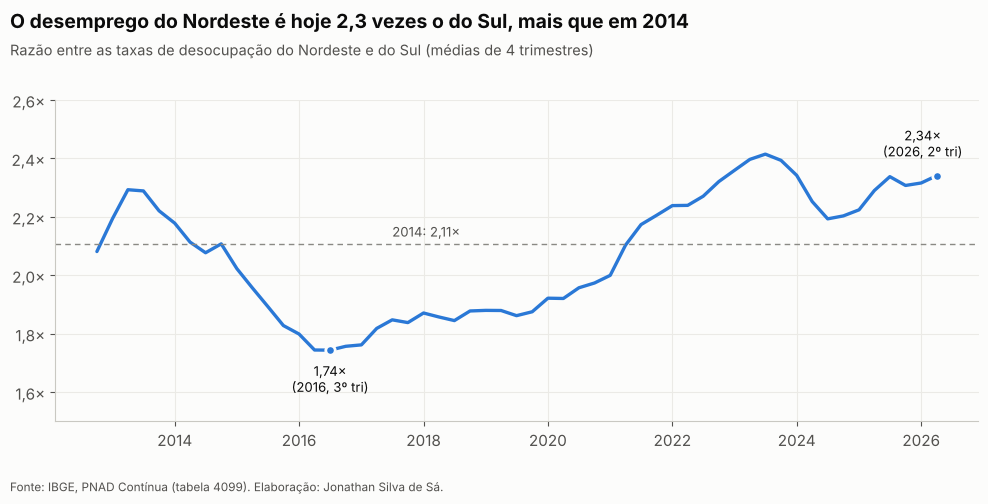

In [12]:
fig, ax = plt.subplots(figsize=(10, 5.2))
x = regioes.index.to_timestamp()
ax.plot(x, regioes["razao_ne_sul"], color=AZUL, lw=2.4)
ax.axhline(regioes.loc[REF_2014, "razao_ne_sul"], color=CINZA, lw=1, ls=(0, (4, 3)))
ax.text(pd.Timestamp("2017-07-01"), regioes.loc[REF_2014, "razao_ne_sul"] + 0.025,
        f"2014: {pct(regioes.loc[REF_2014, 'razao_ne_sul'], 2)}×", color=TEXTO_2, fontsize=9.5)

for p, deslocamento in [(regioes["razao_ne_sul"].idxmin(), (0, -30)), (ULTIMO, (-10, 14))]:
    xp, yp = p.to_timestamp(), regioes.loc[p, "razao_ne_sul"]
    ax.scatter([xp], [yp], s=46, color=AZUL, edgecolor=FUNDO, lw=2, zorder=3)
    ax.annotate(f"{pct(yp, 2)}×\n({p.year}, {p.quarter}º tri)", (xp, yp), xytext=deslocamento,
                textcoords="offset points", ha="center", fontsize=9.5, color=TEXTO)

ax.set_ylim(1.5, 2.6)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.1f}×".replace(".", ",")))
finalizar(fig, "O desemprego do Nordeste é hoje 2,3 vezes o do Sul, mais que em 2014",
          "Razão entre as taxas de desocupação do Nordeste e do Sul (médias de 4 trimestres)",
          "04_nordeste_sul.png")

Em pontos percentuais, a diferença entre Nordeste e Sul é praticamente a mesma de 2014 (cerca de 4,5 p.p.). Mas, como o Sul caiu para pouco mais de 3%, o Nordeste tem hoje 2,3 vezes o desemprego do Sul, contra 2,1 vezes em 2014. Na recessão a razão caiu, porque o Sul foi atingido proporcionalmente mais; na recuperação, o Sul voltou mais rápido.

## 6. Limitações

- **Amostra.** A PNAD Contínua é uma pesquisa amostral. Em estados menores (Amapá, Roraima, Acre) o coeficiente de variação é alto, e diferenças de 1 ponto podem estar dentro da margem de erro. A média de 4 trimestres reduz, mas não elimina, esse ruído.
- **O que a taxa não mede.** Desocupação conta quem procurou trabalho e não achou. Não capta informalidade, subocupação nem quem desistiu de procurar (desalento). Para isso, a mesma tabela traz a taxa composta de subutilização.
- **Causas.** A análise descreve o que aconteceu; as explicações sobre o Rio de Janeiro são contexto, não foram testadas com dados aqui.

## Conclusão

A recuperação do emprego foi ampla: o Brasil está no menor desemprego da série e 18 estados também. Mas ela não foi completa nem igual. Rio de Janeiro, Pernambuco e Piauí ainda estão acima de 2014, e a distância relativa entre o Nordeste e o Sul cresceu. Para quem planeja políticas ou investimentos regionais, a média nacional esconde onde a recuperação ainda não chegou.